# Introduction

### 1.1 Background

Retail revenue is shaped by decisions that are, to a significant extent, within a retailer's own control, and the most important decision are pricing and discounting. Research using large-scale, multi-category retail data has found that retail prices are driven far more by a retailer's own pricing history, wholesale costs, and brand-level demand than by direct competitor price-matching, with competitor pricing accounting for less than 10% of price variation over time as competitive retailer prices account for less than 10% of the over-time variation in retail prices, with pricing history, wholesale price, and brand demand instead identified as the main drivers of retail-price variation (Nijs, Srinivasan and Pauwels, 2007). This supports treating pricing and discount patterns in transaction data as a reflection of deliberate retailer strategy rather than pure market noise.

Discounting itself has a well-documented but time-bound effect on demand. Studies using multivariate time-series analysis across hundreds of product categories have found that price promotions do increase short-term category demand, but that this effect fades within a matter of weeks rather than persisting, with promotional effects found to dissipate over roughly ten weeks and show little long-run impact, while being notably stronger in perishable product categories (Nijs et al., 2001). This is consistent with broader evidence from U.S. retail markets that a substantial share of price variation across stores and time is attributable to promotional activity rather than persistent base-price differences, with a large degree of price dispersion documented across products and stores, driven by both base-price differences and the structure of promotional activity (Hitsch, Hortaçsu and Lin, 2021). Together, this literature suggests discount depth and timing are a legitimate and well-precedented line of inquiry for explaining revenue variation in this dataset, rather than an arbitrary variable to test.

A second, equally important strand of literature concerns the reliability of the transaction data itself. Missing values are recognised as a pervasive and often under-addressed problem in empirical business and information-systems research, with recent reviews of published studies finding that missing data is common, that the proportion missing is frequently non-trivial, and that it is often handled using methods already known to produce biased results, with missing values found to be a pervasive problem in empirical research, non-trivial in extent, and frequently handled using methods that are known to produce biased results (Peng, Hahn and Huang, 2023). The same research emphasises that the bias introduced by missing data is a more serious concern than its volume alone, since a biased pattern of missingness cannot be corrected simply by analysing more data, with the bias caused by missing values identified as the central concern, precisely because it cannot be resolved merely by increasing sample size (Peng, Hahn and Huang, 2023).

Taken together, this literature supports two expectations for the present investigation: first, that pricing, discounting, category, and channel variation are plausible and well-precedented drivers of retail revenue worth testing directly against this dataset; and second, that the substantial missingness identified during the data audit cannot be treated as a minor technical inconvenience to be cleaned away but must be characterised and accounted for as part of the analysis itself, consistent with current guidance on handling missing data in business research.

### 1.2 Problem Statement

This report investigates a transaction-level retail sales dataset spanning January 2024 to May 2025, covering four product categories (Clothing, Electronics, Groceries, Furniture), four regions, and three sales channels. An initial data quality audit revealed that 52% of logged orders (260 of 500) are missing either the quantity sold or the unit price, meaning revenue could not be calculated for just over half of the recorded transactions. Further investigation established that these gaps could not be reliably recovered through imputation: unit price, in particular, showed no consistent relationship to product, region, or any other recorded attribute, ruling out a defensible estimate.

This finding reframes the task facing the group. Rather than a straightforward exercise in identifying revenue drivers, the investigation must first establish how much of the available data can be trusted to answer a revenue question at all, and whether the pattern of missing data is itself informative for instance, if incomplete records are concentrated in a particular channel, region, or time period, this would point to an operational or data-capture issue worth raising independently of the revenue analysis itself.

### 1.3 Research Question

The investigation is guided by the question: what factors appear to influence revenue performance within this retail environment, and to what extent can the transaction data provide reliable evidence for strategic decisions regarding products, regions, and sales channels?

This is addressed through two linked sub-questions:

- Among transactions with complete revenue data, what is associated with higher or lower revenue, product category, region, sales channel, discount level, or quantity purchased and which of these relationships hold up once the others are accounted for?
- Is the incompleteness in the dataset randomly distributed, or does it follow a pattern that itself constitutes a finding relevant to the business?

## 1.4 Rationale and Significance

Answering these questions matters beyond the immediate dataset. For the business represented in this data, understanding genuine revenue drivers as distinct from superficial associations  determines whether strategic resources (stock, marketing spend, regional investment) are allocated effectively. For the group's purposes, the exercise demonstrates a core competency expected at this level: the ability to move from raw, imperfect data to a defensible, evidence-based argument, while being transparent about the limitations of that evidence rather than overstating what the data can support.

## 1.5 Scope and Limitations

The analysis is confined to the 500 transactions provided and does not draw on external sales data, inventory records, or customer-level histories beyond what is captured in the dataset. Given that only 240 of 500 transactions contain complete revenue information, findings relating specifically to revenue are based on this reduced subset; findings relating to order volume, frequency, or the pattern of missing data draw on the full 500 records. Any relationships identified are treated as associative rather than causal unless independently supported by reasoning or external literature, consistent with the critical-thinking standard required of this investigation.

In [106]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
warning = False
import matplotlib as mpl
mpl.rcdefaults()
plt.style.use('default')

In [107]:
transact = pd.read_csv("Retail Sales Transactions 2024-2025.csv")


In [108]:
transact.head(5)

,Order_ID,Customer_Name,Gender,Category,Product,Quantity,Unit_Price,Discount,Order_Date,Sales_Channel,Region,Phone,Product_Name_Duplicate
0,1000,Riya,Female,Clothing,Jacket,1.0,199.0,10.0,01-25-2024,Wholesale,NaN,9876543210,Jacket
1,1001,Sam,Female,GROCERIES,Rice,4.0,499.0,0.0,10-26-2024,Retail,NaN,NaN,Rice
2,1002,Sam,NaN,electronics,Tablet,NaN,499.0,NaN,01/02/24,Wholesale,South,9876543210,Tablet
3,1003,John,Male,Electronics,Mobile,NaN,NaN,5.0,03-27-2024,Retail,East,9876543210,Mobile
4,1004,John,Female,CLOTHING,Shirt,5.0,NaN,10.0,08-30-2024,Retail,West,NaN,Shirt


In [109]:
transact.isnull().sum()

Order_ID                    0
Customer_Name               0
Gender                    165
Category                    0
Product                     0
Quantity                  150
Unit_Price                160
Discount                  183
Order_Date                  0
Sales_Channel             118
Region                     99
Phone                     203
Product_Name_Duplicate      0
dtype: int64

In [110]:
# check the size of the data
transact.shape

(500, 13)

In [111]:
# check data types
transact.dtypes

Order_ID                    int64
Customer_Name              object
Gender                     object
Category                   object
Product                    object
Quantity                  float64
Unit_Price                float64
Discount                  float64
Order_Date                 object
Sales_Channel              object
Region                     object
Phone                      object
Product_Name_Duplicate     object
dtype: object

In [112]:
# missing percentage
missing_percentage = transact.isnull().sum() / len(transact) * 100
print("Missing percentage:")
print(missing_percentage)

Missing percentage:
Order_ID                   0.0
Customer_Name              0.0
Gender                    33.0
Category                   0.0
Product                    0.0
Quantity                  30.0
Unit_Price                32.0
Discount                  36.6
Order_Date                 0.0
Sales_Channel             23.6
Region                    19.8
Phone                     40.6
Product_Name_Duplicate     0.0
dtype: float64


In [113]:
# show distinct products, unit_price, Category, Sales_channel sort by Product column then Product column then Sales_channel
transact[['Product', 'Unit_Price', 'Category', 'Sales_Channel','Region']].drop_duplicates().sort_values(by=["Product", "Region", "Product", "Sales_Channel"])

,Product,Unit_Price,Category,Sales_Channel,Region
102,Apples,199.0,Groceries,Retail,East
77,Apples,199.0,Groceries,Wholesale,East
194,Apples,1500.0,GROCERIES,NaN,East
245,Apples,1500.0,Groceries,NaN,East
325,Apples,NaN,GROCERIES,NaN,East
...,...,...,...,...,...
389,Tablet,499.0,electronics,Retail,NaN
7,Tablet,NaN,electronics,Wholesale,NaN
296,Tablet,999.0,Electronics,Wholesale,NaN
395,Tablet,1500.0,Electronics,Wholesale,NaN


In [114]:
# find the mode of the Product column, Sales_chanel and Region column
print("The mode of Product is:", transact['Product'].mode())
print("The mode of Sales_channel is:", transact['Sales_Channel'].mode())
print("The mode of Region is:", transact['Region'].mode())

The mode of Product is: 0    Rice
Name: Product, dtype: object
The mode of Sales_channel is: 0    Retail
Name: Sales_Channel, dtype: object
The mode of Region is: 0     East
1    North
Name: Region, dtype: object


**Missing value analysis**

In [115]:
# Impute other for null valuesin "Gender" column
transact['Gender'].fillna('Other', inplace=True)

# impute 0 for null values in Quantity, Discount and Unit_Price columns
# assumption is that if the value is null, it means that there was no quantity sold, no discount applied and no unit price for that product
transact['Quantity'].fillna(0, inplace=True)
transact['Discount'].fillna(0, inplace=True)
transact['Unit_Price'].fillna(0, inplace=True)

C:\Users\TshushaP\AppData\Local\Temp\ipykernel_26952\1469038491.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  transact['Gender'].fillna('Other', inplace=True)
C:\Users\TshushaP\AppData\Local\Temp\ipykernel_26952\1469038491.py:6: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

F

In [116]:
# for Sales_channel and Region columns, we will impute "Unknown" for null values
transact['Sales_Channel'].fillna('Unknown', inplace=True)
transact['Region'].fillna('Unknown', inplace=True)

C:\Users\TshushaP\AppData\Local\Temp\ipykernel_26952\4210007053.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  transact['Sales_Channel'].fillna('Unknown', inplace=True)
C:\Users\TshushaP\AppData\Local\Temp\ipykernel_26952\4210007053.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a

In [117]:
transact.isnull().sum()

Order_ID                    0
Customer_Name               0
Gender                      0
Category                    0
Product                     0
Quantity                    0
Unit_Price                  0
Discount                    0
Order_Date                  0
Sales_Channel               0
Region                      0
Phone                     203
Product_Name_Duplicate      0
dtype: int64

**DATA MANIPULATIONS**

In [118]:
# create a new column Sales_Amount which is the product of Quantity and Unit_Price
transact['Sales_Amount'] = transact['Quantity'] * transact['Unit_Price']


In [119]:
# Create a new column Discount_Amount which is the product of Discount/100 * Sales_Amount
transact['Discount_Amount'] = (transact['Discount']/100) * transact['Sales_Amount']

In [120]:
# Create a new column Net_Sales_Amount which is the product of Sales_Amount - Discount_Amount
transact['Net_Sales_Amount'] = transact['Sales_Amount'] - transact['Discount_Amount']

# Create Customer_info column = Customer_Name +"-" Phone
Customer_info = transact['Customer_Name'] + "-" + transact['Phone']

In [121]:
transact.head()

,Order_ID,Customer_Name,Gender,Category,Product,Quantity,Unit_Price,Discount,Order_Date,Sales_Channel,Region,Phone,Product_Name_Duplicate,Sales_Amount,Discount_Amount,Net_Sales_Amount
0,1000,Riya,Female,Clothing,Jacket,1.0,199.0,10.0,01-25-2024,Wholesale,Unknown,9876543210,Jacket,199.0,19.9,179.1
1,1001,Sam,Female,GROCERIES,Rice,4.0,499.0,0.0,10-26-2024,Retail,Unknown,NaN,Rice,1996.0,0.0,1996.0
2,1002,Sam,Other,electronics,Tablet,0.0,499.0,0.0,01/02/24,Wholesale,South,9876543210,Tablet,0.0,0.0,0.0
3,1003,John,Male,Electronics,Mobile,0.0,0.0,5.0,03-27-2024,Retail,East,9876543210,Mobile,0.0,0.0,0.0
4,1004,John,Female,CLOTHING,Shirt,5.0,0.0,10.0,08-30-2024,Retail,West,NaN,Shirt,0.0,0.0,0.0


In [122]:
# export the cleaned data to a new CSV file
transact.to_csv("Retail_Sales_Transactions_Cleaned.csv", index=False)

In [123]:
# Standardise Category: strip whitespace, unify case 
transact['Category'] = transact['Category'].str.strip().str.title()
transact['Category'].value_counts()


Category
Groceries      162
Electronics    143
Clothing       131
Furniture       64
Name: count, dtype: int64

In [124]:
#  Parse Order_Date into a single datetime column.
def parse_order_date(d):
    d = str(d).strip()
    for fmt in ('%m-%d-%Y', '%m/%d/%y'):
        try:
            return pd.to_datetime(d, format=fmt)
        except ValueError:
            continue
    return pd.NaT

transact['Order_Date'] = transact['Order_Date'].apply(parse_order_date)
transact['Order_Month'] = transact['Order_Date'].dt.to_period('M')
print('Unparsed dates:', transact['Order_Date'].isna().sum())
print('Date range:', transact['Order_Date'].min(), 'to', transact['Order_Date'].max())


Unparsed dates: 0
Date range: 2024-01-01 00:00:00 to 2025-05-15 00:00:00


In [125]:
# Drop Product_Name_Duplicate
assert (transact['Product'] == transact['Product_Name_Duplicate']).all()
transact = transact.drop(columns=['Product_Name_Duplicate'])


In [126]:
# Flag rows that represent an actual completed sale vs a zero-quantity/zero-price non-transaction
transact['Valid_Sale'] = (transact['Quantity'] > 0) & (transact['Unit_Price'] > 0)
print(transact['Valid_Sale'].value_counts())
print(f"{(~transact['Valid_Sale']).mean():.1%} of logged orders resulted in no sale")


Valid_Sale
False    260
True     240
Name: count, dtype: int64
52.0% of logged orders resulted in no sale


In [127]:
# Breakdown of why a row is not a valid sale: missing price only, missing quantity only, or both
qty_only_missing = ((transact['Quantity'] > 0) & (transact['Unit_Price'] == 0)).sum()
price_only_missing = ((transact['Unit_Price'] > 0) & (transact['Quantity'] == 0)).sum()
both_missing = ((transact['Quantity'] == 0) & (transact['Unit_Price'] == 0)).sum()

print(f"Quantity known, Unit_Price missing: {qty_only_missing}")
print(f"Unit_Price known, Quantity missing: {price_only_missing}")
print(f"Both missing: {both_missing}")
print(f"Total non-valid: {qty_only_missing + price_only_missing + both_missing} (should equal {(~transact['Valid_Sale']).sum()})")

Quantity known, Unit_Price missing: 110
Unit_Price known, Quantity missing: 100
Both missing: 50
Total non-valid: 260 (should equal 260)


In [128]:
transact.to_csv('Retail_Sales_Transactions_Analysis_Ready.csv', index=False)
transact.head()


,Order_ID,Customer_Name,Gender,Category,Product,Quantity,Unit_Price,Discount,Order_Date,Sales_Channel,Region,Phone,Sales_Amount,Discount_Amount,Net_Sales_Amount,Order_Month,Valid_Sale
0,1000,Riya,Female,Clothing,Jacket,1.0,199.0,10.0,2024-01-25,Wholesale,Unknown,9876543210,199.0,19.9,179.1,2024-01,True
1,1001,Sam,Female,Groceries,Rice,4.0,499.0,0.0,2024-10-26,Retail,Unknown,NaN,1996.0,0.0,1996.0,2024-10,True
2,1002,Sam,Other,Electronics,Tablet,0.0,499.0,0.0,2024-01-02,Wholesale,South,9876543210,0.0,0.0,0.0,2024-01,False
3,1003,John,Male,Electronics,Mobile,0.0,0.0,5.0,2024-03-27,Retail,East,9876543210,0.0,0.0,0.0,2024-03,False
4,1004,John,Female,Clothing,Shirt,5.0,0.0,10.0,2024-08-30,Retail,West,NaN,0.0,0.0,0.0,2024-08,False


# Exploratory Data Analysis

In [129]:
from scipy.stats import chi2_contingency
import numpy as np

known = transact[transact['Unit_Price'] > 0].reset_index(drop=True)
print(known['Unit_Price'].value_counts(normalize=True))   # 4 discrete price tiers

# 1. Is price tier associated with any field? (chi-square + Cramér's V)
for col in ['Customer_Name', 'Product', 'Category', 'Region', 'Sales_Channel', 'Gender']:
    ct = pd.crosstab(known[col], known['Unit_Price'])
    chi2, p, _, _ = chi2_contingency(ct)
    v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
    print(f"{col:15s} p={p:.3f}  Cramer's V={v:.3f}")



Unit_Price
499.0     0.279412
1500.0    0.250000
199.0     0.238235
999.0     0.232353
Name: proportion, dtype: float64
Customer_Name   p=0.989  Cramer's V=0.113
Product         p=0.716  Cramer's V=0.166
Category        p=0.368  Cramer's V=0.098
Region          p=0.213  Cramer's V=0.123
Sales_Channel   p=0.410  Cramer's V=0.095
Gender          p=0.482  Cramer's V=0.090


In [130]:
# 2. Would a lookup rule actually predict price?
def loo_accuracy(keys):
    hits = 0
    for i, row in known.iterrows():
        others = known.drop(i)
        match = others
        for k in keys:
            match = match[match[k] == row[k]]
        pool = match if len(match) > 0 else others
        hits += (pool['Unit_Price'].mode().iloc[0] == row['Unit_Price'])
    return hits / len(known)

baseline = known['Unit_Price'].value_counts(normalize=True).max()
print('Baseline (always guess the most common price):', round(baseline, 3))
for keys in [['Product'], ['Customer_Name'], ['Customer_Name', 'Product']]:
    print(keys, round(loo_accuracy(keys), 3))

Baseline (always guess the most common price): 0.279
['Product'] 0.265
['Customer_Name'] 0.265
['Customer_Name', 'Product'] 0.256


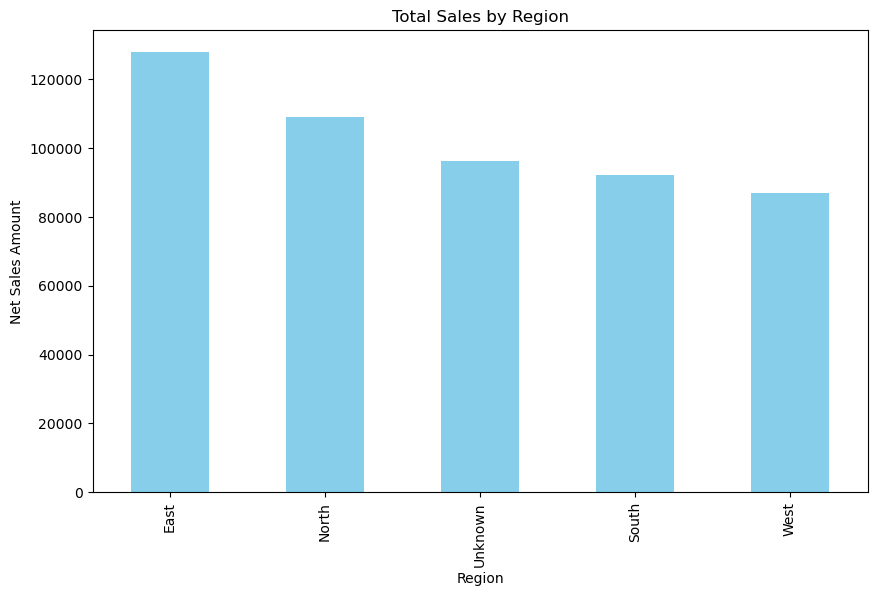

In [131]:
# Total sales by region
# uses full dataset; the 260 incomplete rows have Net_Sales_Amount = 0 and don't distort totals
sales_by_region = transact.groupby('Region')['Net_Sales_Amount'].sum().sort_values(ascending=False)
plt.figure(figsize=(10,6))
sales_by_region.plot(kind='bar', color='skyblue')
plt.title('Total Sales by Region')
plt.xlabel('Region')
plt.ylabel('Net Sales Amount')
plt.show()


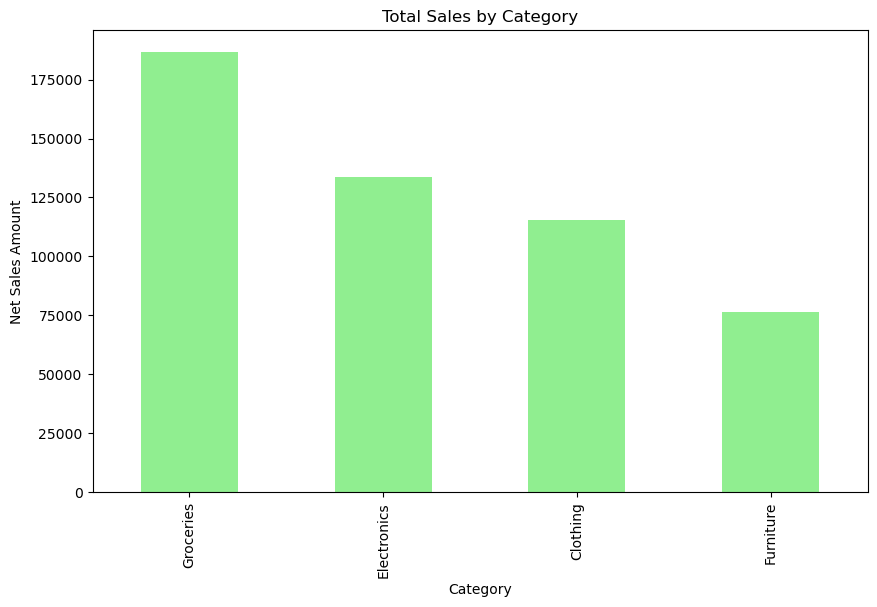

In [132]:
# total sales by category
# uses full dataset; the 260 incomplete rows have Net_Sales_Amount = 0 and don't distort totals
sales_by_category = transact.groupby('Category')['Net_Sales_Amount'].sum().sort_values(ascending=False)
plt.figure(figsize=(10,6))
sales_by_category.plot(kind='bar', color='lightgreen')
plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Net Sales Amount')
plt.show()


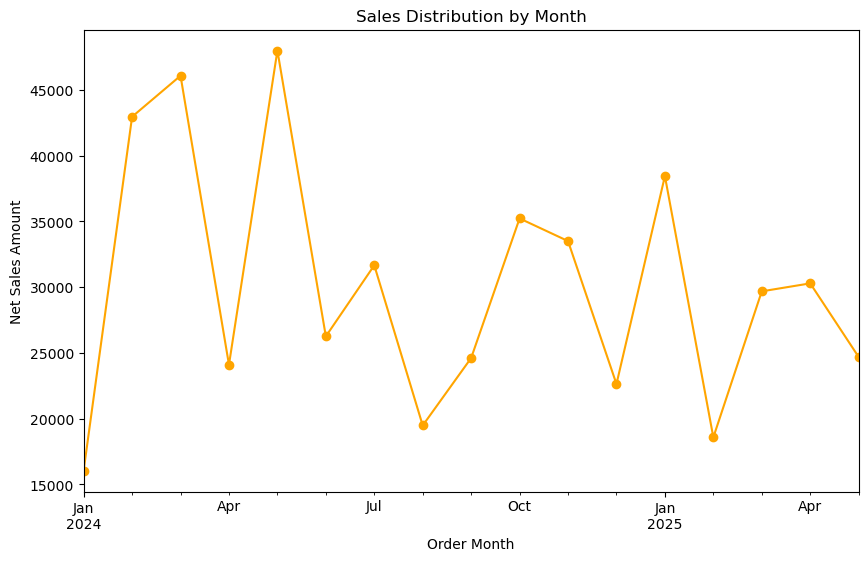

In [133]:
# sales ditribution by month
# uses full dataset; the 260 incomplete rows have Net_Sales_Amount = 0 and don't distort totals
sales_by_month = transact.groupby('Order_Month')['Net_Sales_Amount'].sum().sort_index()
plt.figure(figsize=(10,6))
sales_by_month.plot(kind='line', marker='o', color='orange')
plt.title('Sales Distribution by Month')
plt.xlabel('Order Month')
plt.ylabel('Net Sales Amount')
plt.show()


In [134]:
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge
import numpy as np


transact_mi = transact.copy()
transact_mi.loc[transact_mi['Quantity'] == 0, 'Quantity'] = np.nan
transact_mi.loc[transact_mi['Unit_Price'] == 0, 'Unit_Price'] = np.nan

cols_to_impute = ['Quantity', 'Unit_Price', 'Discount']

bounds = {
    'Quantity': (1, transact_mi['Quantity'].max()),
    'Unit_Price': (0.01, transact_mi['Unit_Price'].max()),
    'Discount': (0, transact_mi['Discount'].max())
}

# Generate 5 separate imputed datasets (standard MI practice), each with different random draws
imputed_versions = []
for i in range(5):
    imputer = IterativeImputer(estimator=BayesianRidge(), sample_posterior=True, random_state=i)
    imputed_array = imputer.fit_transform(transact_mi[cols_to_impute])
    version = transact_mi.copy()
    version[cols_to_impute] = imputed_array
    for col, (lo, hi) in bounds.items():
        version[col] = version[col].clip(lower=lo, upper=hi)
    
    version['Net_Sales_Amount'] = version['Quantity'] * version['Unit_Price'] * (1 - version['Discount'] / 100)
    imputed_versions.append(version)
    
pooled = transact_mi.copy()
for col in cols_to_impute:
    pooled[col] = np.mean([v[col] for v in imputed_versions], axis=0)
pooled['Net_Sales_Amount'] = pooled['Quantity'] * pooled['Unit_Price'] * (1 - pooled['Discount'] / 100)


## Testing whether the missingness is patterned (MAR test)



In [135]:
from scipy.stats import chi2_contingency

transact['Missing'] = ~transact['Valid_Sale']

missingness_results = []
for col in ['Category', 'Region', 'Sales_Channel', 'Order_Month']:
    ct = pd.crosstab(transact[col], transact['Missing'])
    chi2, p, dof, exp = chi2_contingency(ct)
    missingness_results.append({'Variable': col, 'Chi2': round(chi2, 2), 'p_value': round(p, 4)})
    print(f"{col}: chi2={chi2:.2f}, p={p:.4f}")

pd.DataFrame(missingness_results)


Category: chi2=0.45, p=0.9302
Region: chi2=0.67, p=0.9550
Sales_Channel: chi2=3.00, p=0.3915
Order_Month: chi2=15.54, p=0.4853


,Variable,Chi2,p_value
0,Category,0.45,0.9302
1,Region,0.67,0.9550
2,Sales_Channel,3.00,0.3915
3,Order_Month,15.54,0.4853


**Result:** none of the four tests are significant at p < 0.05 (all p > 0.3). The missingness does not vary meaningfully by category, region, channel, or month, which does not prove MCAR but gives us no evidence against it across every observed variable available. 

# Data Quality (52% Missingness)

- 260 of 500 orders (52%) have missing Quantity, Unit_Price, or both

- 110 orders have quantity but no price, 100 have price but no quantity, 50 have neither

- Only 240 orders (48%) are "valid sales" with computable revenue

- Chi-square tests against Category, Region, Sales_Channel, and Order_Month all returned non-significant p-values (all p > 0.3).

## Intepretation
The missingness is not patterned by any observed variable. This is consistent with MCAR (Missing Completely At Random)  or at least, we have no evidence against it. Therefore, complete-case analysis (n=240) is likely unbiased, just less powerful. in conclusion if missingness had clustered in either Online or East, then the complete-case revenue figures would be systematically wrong for those segments. additionally, we note that MCAR could not be proven, we only failed to be reject the possinility. The missingness could still depend on an unobserved variable and/or system glitch, but within the data provided, the pattern looks random.

## Comparing complete-case analysis against the MI-pooled dataset


In [136]:
complete_case = transact[transact['Valid_Sale']]

comparison_category = pd.DataFrame({
    'Complete_Case_Revenue': complete_case.groupby('Category')['Net_Sales_Amount'].sum(),
    'MI_Pooled_Revenue': pooled.groupby('Category')['Net_Sales_Amount'].sum()
}).sort_values('Complete_Case_Revenue', ascending=False)
comparison_category['Complete_Case_Rank'] = comparison_category['Complete_Case_Revenue'].rank(ascending=False)
comparison_category['MI_Pooled_Rank'] = comparison_category['MI_Pooled_Revenue'].rank(ascending=False)
print(comparison_category)


             Complete_Case_Revenue  MI_Pooled_Revenue  Complete_Case_Rank  \
Category                                                                    
Groceries                186681.80      372746.045158                 1.0   
Electronics              133741.45      305033.405733                 2.0   
Clothing                 115447.20      268636.112283                 3.0   
Furniture                 76313.40      148407.632489                 4.0   

             MI_Pooled_Rank  
Category                     
Groceries               1.0  
Electronics             2.0  
Clothing                3.0  
Furniture               4.0  


In [137]:
from scipy import stats

complete_case = transact[transact['Valid_Sale']].copy()
complete_case["Order_Date"] = pd.to_datetime(complete_case["Order_Date"])

print("All orders: ", len(transact),'| complete-case orders:', len(complete_case))
print("Date Range:",transact['Order_Date'].min(), "to", transact['Order_Date'].max().date())

def group_summary(df, col, value="Net_Sales_Amount"):
    t = df.groupby(col)[value].agg(Orders = 'count', Total_Revenue = 'sum',
                                   Mean_Order_Value = "mean", Median_Order_Value = "median").round(0)
    t["Revenue_Share_%"] = (t["Total_Revenue"] / t["Total_Revenue"].sum() * 100).round(1)
    return t.sort_values("Total_Revenue", ascending=False)

def kruskal_summary(df, col, value="Net_Sales_Amount"):
    groups = [g[value].values for _, g in df.groupby(col)]
    H, p = stats.kruskal(*groups)
    n, k = len(df), len(groups)
    eps2 = max(0, (H - k + 1) / (n - k))  # epsilon-squared effect size
    return H, p, eps2

All orders:  500 | complete-case orders: 240
Date Range: 2024-01-01 00:00:00 to 2025-05-15


# 1. How Revenue is genereated: distribution of order value

,Quantity,Unit_Price,Discount,Sales_Amount,Discount_Amount,Net_Sales_Amount
count,240.0,240.0,240.0,240.0,240.0,240.0
mean,2.9,783.4,4.5,2247.8,113.7,2134.1
std,1.5,498.7,5.6,1915.4,218.6,1803.1
min,1.0,199.0,0.0,199.0,0.0,169.2
25%,2.0,199.0,0.0,995.0,0.0,883.9
50%,3.0,499.0,0.0,1497.0,0.0,1497.0
75%,4.0,1124.2,10.0,3000.0,149.2,2997.0
max,5.0,1500.0,15.0,7500.0,1125.0,7500.0


Total net revenue: 512,184 | mean order value: 2,134 | median: 1,497
Skewness: 1.18 | Shapiro-Wilk p = 6.7e-14 (p < 0.05 -> not normal)
Discount given (lower bound, see discount section): 27,294 = 5.1% of gross sales


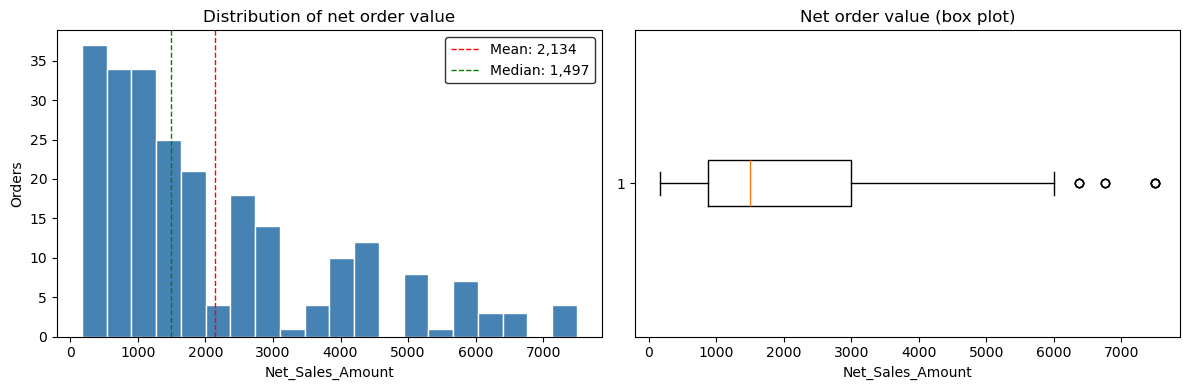

In [138]:
num_cols = ["Quantity", "Unit_Price", "Discount", "Sales_Amount", "Discount_Amount", "Net_Sales_Amount"]
display(complete_case[num_cols].describe().round(1))

rev = complete_case["Net_Sales_Amount"]
print(f"Total net revenue: {rev.sum():,.0f} | mean order value: {rev.mean():,.0f} | median: {rev.median():,.0f}")
print(f"Skewness: {rev.skew():.2f} | Shapiro-Wilk p = {stats.shapiro(rev).pvalue:.2g} (p < 0.05 -> not normal)")
print(f"Discount given (lower bound, see discount section): {complete_case['Discount_Amount'].sum():,.0f} "
      f"= {complete_case['Discount_Amount'].sum() / complete_case['Sales_Amount'].sum():.1%} of gross sales")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(rev, bins=20, color='steelblue', edgecolor='white')
ax[0].axvline(rev.mean(), color='red', linestyle='dashed', linewidth=1, label=f'Mean: {rev.mean():,.0f}')
ax[0].axvline(rev.median(), color='green', linestyle='dashed', linewidth=1, label=f'Median: {rev.median():,.0f}')
ax[0].legend(loc='upper right', edgecolor='black', fontsize=10)
ax[0].set_title('Distribution of net order value'); ax[0].set_xlabel('Net_Sales_Amount'); ax[0].set_ylabel('Orders')
ax[1].boxplot(rev, vert=False); ax[1].set_title('Net order value (box plot)'); ax[1].set_xlabel('Net_Sales_Amount')
plt.tight_layout(); plt.show()

# 2. Price, Quanity and Revenue

,Variable,Pearson_r,Pearson_p,Spearman_rho,Spearman_p
0,Unit_Price,0.747,4.3e-44,0.804,9.3e-56
1,Quantity,0.500,1.3e-16,0.486,1.2e-15


Unit_Price vs Quantity (do customers buy fewer units at higher prices?): rho = -0.069, p = 0.284

Unit_Price takes only these values: [np.float64(199.0), np.float64(499.0), np.float64(999.0), np.float64(1500.0)]


,Orders,Mean_Revenue
Unit_Price,,
199.0,61,596.0
499.0,66,1471.0
999.0,53,2333.0
1500.0,60,4251.0


,Orders,Mean_Revenue
Quantity,,
1.0,57,711.0
2.0,43,1642.0
3.0,48,2477.0
4.0,44,3073.0
5.0,48,3061.0


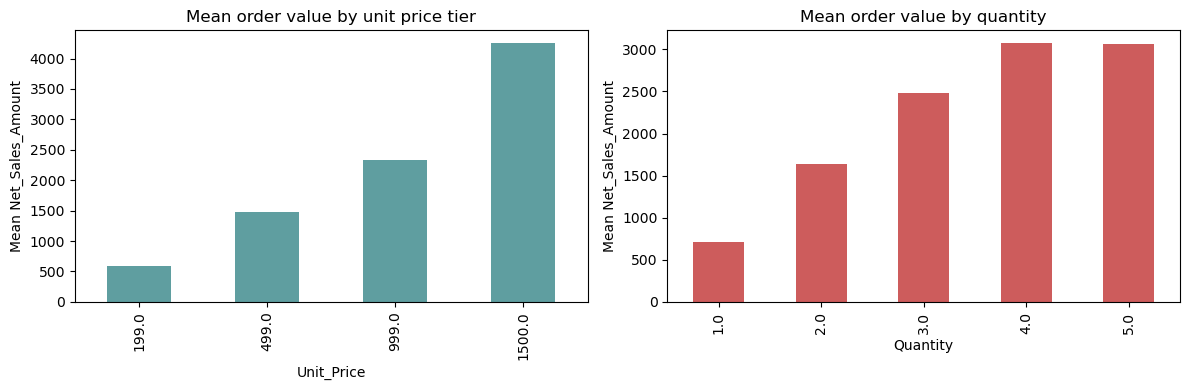

In [139]:
rows = []
for var in ['Unit_Price', 'Quantity']:
    r, p = stats.pearsonr(complete_case[var], rev)
    rho, ps = stats.spearmanr(complete_case[var], rev)
    rows.append({'Variable': var, 'Pearson_r': round(r, 3), 'Pearson_p': f'{p:.2g}',
                 'Spearman_rho': round(rho, 3), 'Spearman_p': f'{ps:.2g}'})
display(pd.DataFrame(rows))

rho, p = stats.spearmanr(complete_case['Unit_Price'], complete_case['Quantity'])
print(f"Unit_Price vs Quantity (do customers buy fewer units at higher prices?): rho = {rho:.3f}, p = {p:.3f}")

print('\nUnit_Price takes only these values:', sorted(complete_case['Unit_Price'].unique()))
display(complete_case.groupby('Unit_Price')['Net_Sales_Amount'].agg(Orders='count', Mean_Revenue='mean').round(0))
display(complete_case.groupby('Quantity')['Net_Sales_Amount'].agg(Orders='count', Mean_Revenue='mean').round(0))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
complete_case.groupby('Unit_Price')['Net_Sales_Amount'].mean().plot(kind='bar', ax=ax[0], color='cadetblue')
ax[0].set_title('Mean order value by unit price tier'); ax[0].set_ylabel('Mean Net_Sales_Amount')
complete_case.groupby('Quantity')['Net_Sales_Amount'].mean().plot(kind='bar', ax=ax[1], color='indianred')
ax[1].set_title('Mean order value by quantity'); ax[1].set_ylabel('Mean Net_Sales_Amount')
plt.tight_layout(); plt.show()

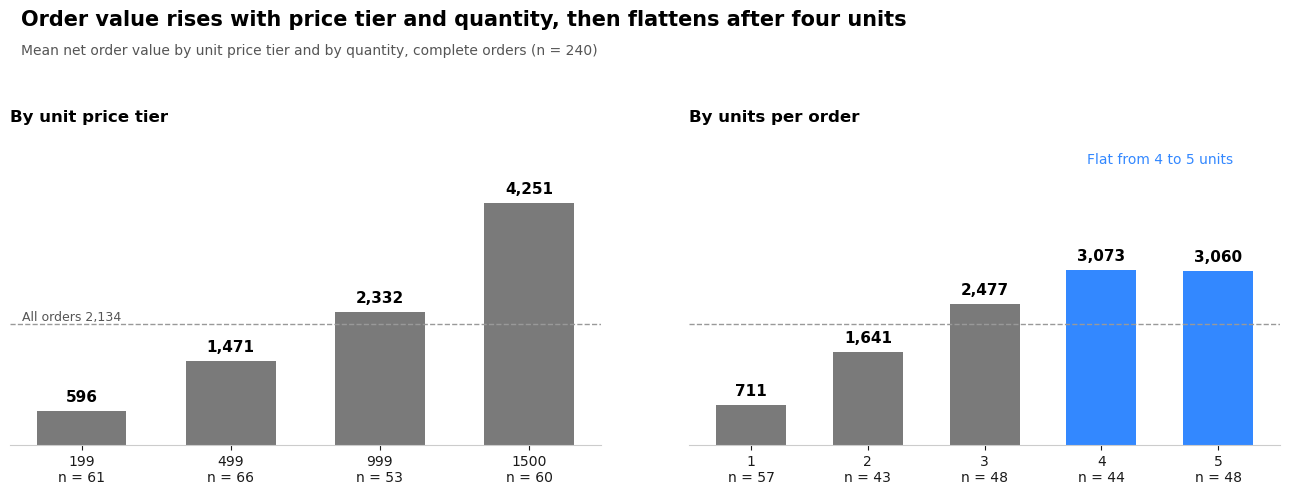

In [140]:
# ---- Aggregations from your data ----
price_grp = complete_case.groupby('Unit_Price')['Net_Sales_Amount'].agg(Orders='count', Mean_Revenue='mean')
qty_grp   = complete_case.groupby('Quantity')['Net_Sales_Amount'].agg(Orders='count', Mean_Revenue='mean')
overall_mean = complete_case['Net_Sales_Amount'].mean()

# Calculate a shared y-limit to ensure both charts scale identically
max_val = max(price_grp['Mean_Revenue'].max(), qty_grp['Mean_Revenue'].max())
ylim_top = max_val * 1.25 # Give 25% headroom for labels and text

# ---- Styling (Light Theme) ----
plt.rcParams.update({
    'figure.facecolor': 'white', 
    'axes.facecolor': 'white',
    'text.color': '#1a1a1a', 
    'axes.labelcolor': '#1a1a1a',
    'xtick.color': '#1a1a1a', 
    'ytick.color': '#1a1a1a',
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

def style_ax(ax, title):
    ax.set_title(title, loc='left', fontsize=12, fontweight='bold', pad=15, color='black')
    ax.set_yticks([])
    for s in ['top', 'right', 'left']:
        ax.spines[s].set_visible(False)
    ax.spines['bottom'].set_color('#cccccc') # Lighter bottom spine
    ax.axhline(overall_mean, color='#999999', ls='--', lw=1)
    ax.set_ylim(0, ylim_top)

# ---- Left: by unit price tier ----
x1 = np.arange(len(price_grp))
ax1.bar(x1, price_grp['Mean_Revenue'].values, color='#7a7a7a', width=0.6) # Lighter grey for light theme
style_ax(ax1, 'By unit price tier')
ax1.set_xticks(x1)
ax1.set_xticklabels([f"{int(p)}\nn = {int(o)}" for p, o in
                     zip(price_grp.index, price_grp['Orders'])], fontsize=10)
for x, v in zip(x1, price_grp['Mean_Revenue'].values):
    ax1.text(x, v + (ylim_top * 0.02), f'{int(v):,}', ha='center', va='bottom',
             fontsize=11, fontweight='bold', color='black')
    
# Annotation for Overall Mean
ax1.text(x1[0] - 0.4, overall_mean + (ylim_top * 0.01), f'All orders {int(overall_mean):,}',
         color='#555555', fontsize=9)

# ---- Right: by units per order ----
x2 = np.arange(len(qty_grp))
colors2 = ['#7a7a7a'] * 3 + ['#3388FF'] * (len(qty_grp) - 3)
ax2.bar(x2, qty_grp['Mean_Revenue'].values, color=colors2, width=0.6)
style_ax(ax2, 'By units per order')
ax2.set_xticks(x2)
ax2.set_xticklabels([f"{int(q)}\nn = {int(o)}" for q, o in
                     zip(qty_grp.index, qty_grp['Orders'])], fontsize=10)
for x, v in zip(x2, qty_grp['Mean_Revenue'].values):
    ax2.text(x, v + (ylim_top * 0.02), f'{int(v):,}', ha='center', va='bottom',
             fontsize=11, fontweight='bold', color='black')

# Annotation for the flattening (Positioned higher to avoid overlap)
if len(qty_grp) >= 5:
    # Placing it slightly above the top of the y-axis limit
    ax2.text(x2[3] + 0.5, ylim_top * 0.93,
             'Flat from 4 to 5 units', color='#3388FF', fontsize=10, ha='center')

# ---- Title & subtitle ----
fig.suptitle('Order value rises with price tier and quantity, then flattens after four units',
             x=0.02, y=0.98, ha='left', fontsize=15, fontweight='bold', color='black')
fig.text(0.02, 0.89,
         f'Mean net order value by unit price tier and by quantity, complete orders (n = {len(complete_case)})',
         ha='left', fontsize=10, color='#555555')

plt.tight_layout(rect=[0, 0, 1, 0.88])
plt.subplots_adjust(wspace=0.15)
plt.show()

# What Drives Revenue? 
**Unit Price is the dominant driver**

- Unit_Price vs revenue: Pearson r = 0.747, Spearman ρ = 0.804, this shows a strong positive relationship between revenue and unit_price.
- Quantity vs revenue: r = 0.500, ρ = 0.486, shows a moderate positive relationship between Quantity and Revenue.
- the results indicate that Unit Price explains far more revenue variance than Quantity.
- Unit_Price and Quantity are essentially uncorrelated (ρ = −0.069, r = 0.284). In normal retail you'd expect higher prices → fewer units bought (demand elasticity). That's not happening here.
- What this means is that the price tiers (199, 499, 999, 1500) don't suppress volume. Customers buying at 1500 buy roughly the same number of units as those buying at 199. This is unusual and suggests either:
  - The "price" field isn't a true retail price (could be a tiered/list price where volume is negotiated separately)
  - The dataset is synthetic and doesn't encode real demand behavior
  - The quantity range is truncated (1–5 units), which compresses the relationship

what this means for a business if true, the revenue growth should focus on pushing higher-priced SKUs, not on volume discounts. But given the suspiciously clean price tiers and the tight quantity range, we  treat this as a data artifact rather than a strategy insight.

# 3. Difference across categories, regions and channels

In [141]:
results = []
for col in ['Category', 'Region', 'Sales_Channel']:
    print(f'===== {col} =====')
    display(group_summary(complete_case, col))
    H, p, eps2 = kruskal_summary(complete_case, col)
    print(f'Kruskal-Wallis on order value: H = {H:.2f}, p = {p:.3f}, epsilon-squared = {eps2:.3f}\n')
    results.append({'Grouping': col, 'H': round(H, 2), 'p_value': round(p, 3), 'epsilon_sq': round(eps2, 3)})
display(pd.DataFrame(results))

===== Category =====


,Orders,Total_Revenue,Mean_Order_Value,Median_Order_Value,Revenue_Share_%
Category,,,,,
Groceries,81,186682.0,2305.0,1996.0,36.4
Electronics,67,133741.0,1996.0,998.0,26.1
Clothing,61,115447.0,1893.0,1272.0,22.5
Furniture,31,76313.0,2462.0,1500.0,14.9


Kruskal-Wallis on order value: H = 4.58, p = 0.206, epsilon-squared = 0.007

===== Region =====


,Orders,Total_Revenue,Mean_Order_Value,Median_Order_Value,Revenue_Share_%
Region,,,,,
East,49,127881.0,2610.0,1500.0,25.0
North,52,109031.0,2097.0,1310.0,21.3
Unknown,45,96264.0,2139.0,1350.0,18.8
South,47,92108.0,1960.0,1500.0,18.0
West,47,86900.0,1849.0,1497.0,17.0


Kruskal-Wallis on order value: H = 1.62, p = 0.805, epsilon-squared = 0.000

===== Sales_Channel =====


,Orders,Total_Revenue,Mean_Order_Value,Median_Order_Value,Revenue_Share_%
Sales_Channel,,,,,
Online,54,137628.0,2549.0,1948.0,26.9
Wholesale,64,136787.0,2137.0,1498.0,26.7
Retail,72,134795.0,1872.0,1311.0,26.3
Unknown,50,102973.0,2059.0,1497.0,20.1


Kruskal-Wallis on order value: H = 2.96, p = 0.398, epsilon-squared = 0.000



,Grouping,H,p_value,epsilon_sq
0,Category,4.58,0.206,0.007
1,Region,1.62,0.805,0.000
2,Sales_Channel,2.96,0.398,0.000


the is no significant difference between Category, Region, Channel
- Category: Kruskal-Wallis H = 4.58, p = 0.206, ε² = 0.007 (essentially zero effect)
- Region: H = 1.62, p = 0.805, ε² = 0.000
- Sales_Channel: H = 2.96, p = 0.398, ε² = 0.000

**Implications** With 240 observations split across 4 categories, 5 regions, and 4 channels, we simply do not have the statistical power to detect moderate effect sizes. The absence of significance is not evidence of absence of effect. The ε² values near zero do suggest that, even if effects exist, they're small.

C:\Users\TshushaP\AppData\Local\Temp\ipykernel_26952\1061387349.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, j].boxplot([complete_case.loc[complete_case[col] == g, 'Net_Sales_Amount'] for g in order], labels=order)
C:\Users\TshushaP\AppData\Local\Temp\ipykernel_26952\1061387349.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, j].boxplot([complete_case.loc[complete_case[col] == g, 'Net_Sales_Amount'] for g in order], labels=order)
C:\Users\TshushaP\AppData\Local\Temp\ipykernel_26952\1061387349.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1, j].boxplot([complete_case.loc[complete_ca

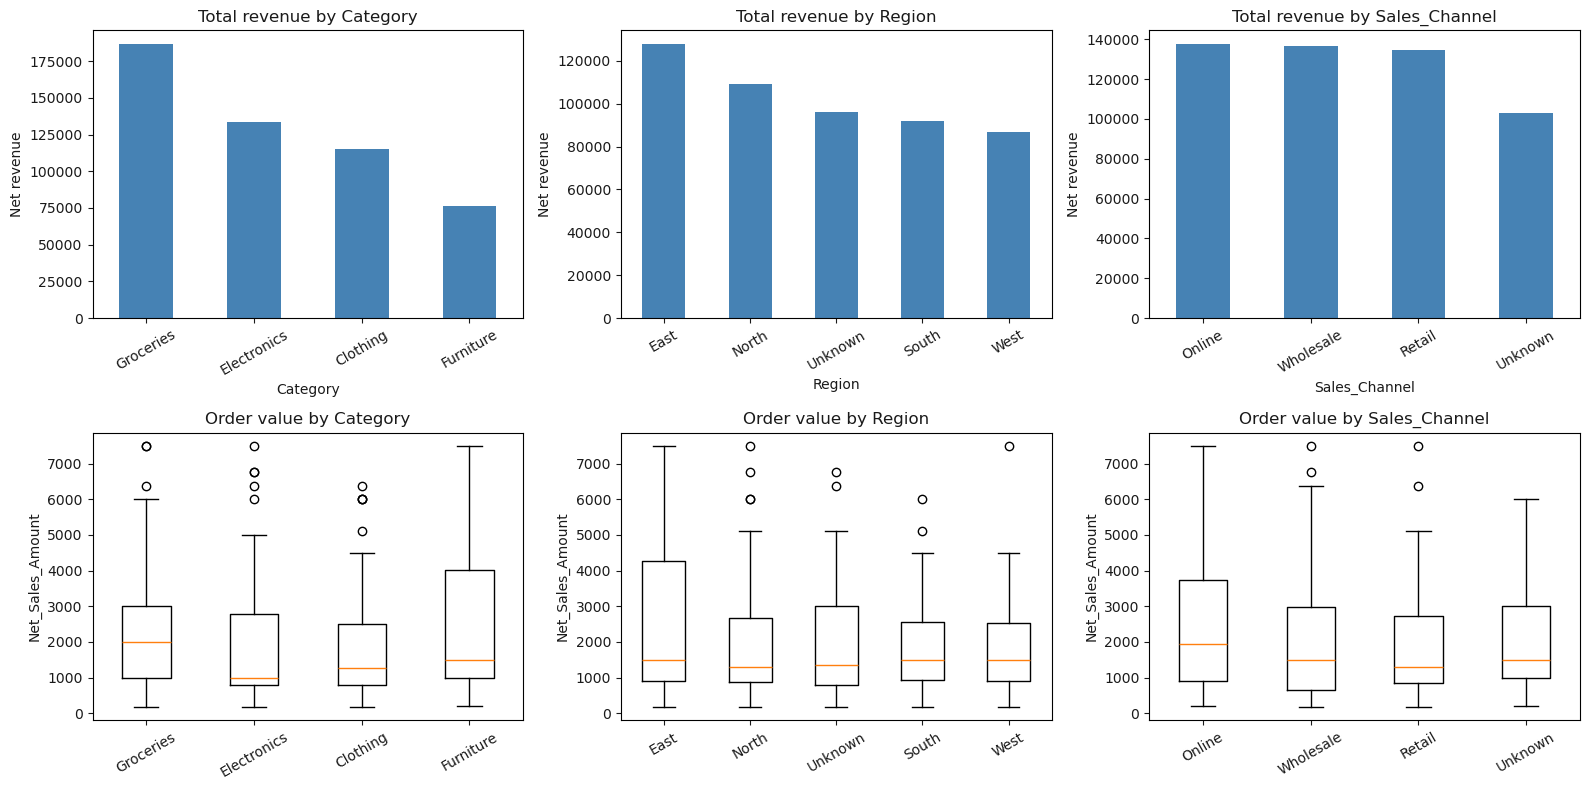

In [142]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, col in enumerate(['Category', 'Region', 'Sales_Channel']):
    tot = group_summary(complete_case, col)['Total_Revenue']
    tot.plot(kind='bar', ax=axes[0, j], color='steelblue')
    axes[0, j].set_title(f'Total revenue by {col}'); axes[0, j].set_ylabel('Net revenue'); axes[0, j].tick_params(axis='x', rotation=30)
    order = list(tot.index)
    axes[1, j].boxplot([complete_case.loc[complete_case[col] == g, 'Net_Sales_Amount'] for g in order], labels=order)
    axes[1, j].set_title(f'Order value by {col}'); axes[1, j].set_ylabel('Net_Sales_Amount'); axes[1, j].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

In [143]:
# Do region and channel combine? Total revenue by Region x Sales_Channel
display(pd.crosstab(complete_case['Region'], complete_case['Sales_Channel'],
                    values=complete_case['Net_Sales_Amount'], aggfunc='sum').round(0))

# Product level
display(complete_case.groupby(['Category', 'Product'])['Net_Sales_Amount']
        .agg(Orders='count', Total_Revenue='sum', Mean_Order_Value='mean').round(0)
        .sort_values('Total_Revenue', ascending=False))

Sales_Channel,Online,Retail,Unknown,Wholesale
Region,,,,
East,43038.0,35685.0,18865.0,30293.0
North,30948.0,24430.0,28614.0,25039.0
South,24516.0,28436.0,15299.0,23856.0
Unknown,21338.0,23611.0,22725.0,28590.0
West,17788.0,22634.0,17469.0,29008.0


Orders  Total_Revenue  Mean_Order_Value
Category    Product                                         
Groceries   Bananas      30        65836.0            2195.0
            Rice         26        60547.0            2329.0
            Apples       25        60298.0            2412.0
Electronics Laptop       26        54425.0            2093.0
Clothing    Jeans        23        48776.0            2121.0
Electronics Tablet       21        42042.0            2002.0
Clothing    Shirt        19        41704.0            2195.0
Electronics Mobile       20        37274.0            1864.0
Furniture   Chair        13        36514.0            2809.0
Clothing    Jacket       19        24967.0            1314.0
Furniture   Desk          9        22387.0            2487.0
            Sofa          9        17412.0            1935.0

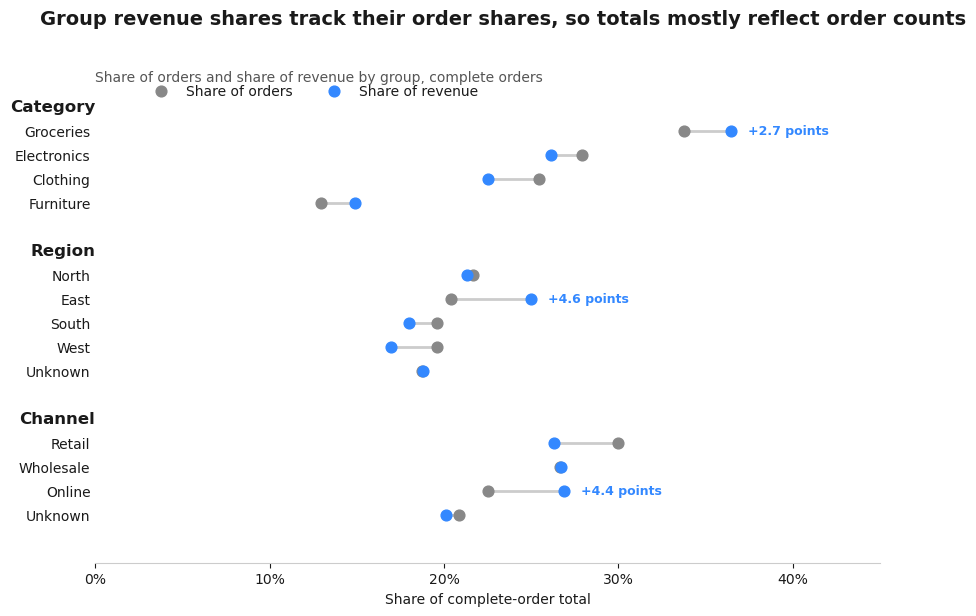

In [144]:
# ---- Calculate Shares ----
df_share = complete_case.copy()
total_orders = len(df_share)
total_rev = df_share['Net_Sales_Amount'].sum()

# Function to calculate shares for a specific column
def get_shares(df, col):
    grp = df.groupby(col).agg(
        Orders=('Order_ID', 'count'),
        Revenue=('Net_Sales_Amount', 'sum')
    )
    grp['Share_of_Orders'] = (grp['Orders'] / total_orders) * 100
    grp['Share_of_Revenue'] = (grp['Revenue'] / total_rev) * 100
    # Sort by Share of Orders descending for visual consistency
    return grp.sort_values('Share_of_Orders', ascending=False)

shares_cat = get_shares(df_share, 'Category')
shares_reg = get_shares(df_share, 'Region')
shares_chan = get_shares(df_share, 'Sales_Channel')

# ---- Plotting ----
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'text.color': '#1a1a1a', 'axes.labelcolor': '#1a1a1a',
                     'xtick.color': '#1a1a1a', 'ytick.color': '#1a1a1a'})

fig, ax = plt.subplots(figsize=(9, 6))

# Create a custom y-axis layout by stacking the groups
y_pos = 0
y_ticks = []
y_labels = []
section_headers = []

# Colors
c_orders = '#888888'
c_rev = '#3388FF'

for title, data in [('Category', shares_cat), ('Region', shares_reg), ('Channel', shares_chan)]:
    section_headers.append((y_pos, title))
    y_pos += 1 # Add space for header
    
    for idx, row in data.iterrows():
        y_ticks.append(y_pos)
        y_labels.append(idx)
        
        # Draw the connecting line
        ax.plot([row['Share_of_Orders'], row['Share_of_Revenue']], [y_pos, y_pos], 
                color='#cccccc', linewidth=2, zorder=1)
        
        # Draw the dots
        ax.scatter(row['Share_of_Orders'], y_pos, color=c_orders, s=60, zorder=2)
        ax.scatter(row['Share_of_Revenue'], y_pos, color=c_rev, s=60, zorder=2)
        
        # Add annotation if Revenue Share is significantly higher than Order Share
        diff = row['Share_of_Revenue'] - row['Share_of_Orders']
        if diff > 2: # Only annotate if over 2 percentage points difference
            ax.text(row['Share_of_Revenue'] + 1, y_pos, 
                    f"+{diff:.1f} points", va='center', color=c_rev, fontsize=9, fontweight='bold')
        
        y_pos += 1
    y_pos += 1 # Space between sections

# Formatting Y-axis
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)
ax.set_ylim(y_pos, -0.5) # Invert Y axis so it reads top-down

# Add section headers
for y, label in section_headers:
    ax.text(0, y, label, fontweight='bold', fontsize=12, va='center', ha='right', transform=ax.get_yaxis_transform())

# Formatting X-axis
ax.set_xlabel('Share of complete-order total', fontsize=10)
ax.set_xlim(0, 45)
ax.set_xticks([0, 10, 20, 30, 40])
ax.set_xticklabels(['0%', '10%', '20%', '30%', '40%'])

# Remove spines
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#cccccc')
ax.tick_params(axis='y', length=0) # Hide y-axis ticks

# Add custom legend manually
ax.scatter([], [], color=c_orders, label='Share of orders', s=60)
ax.scatter([], [], color=c_rev, label='Share of revenue', s=60)
ax.legend(loc='upper left', frameon=False, bbox_to_anchor=(0.05, 1.05), ncol=2)

# Titles
plt.suptitle('Group revenue shares track their order shares, so totals mostly reflect order counts', 
             x=0.05, y=1.02, ha='left', fontsize=14, fontweight='bold')
ax.set_title('Share of orders and share of revenue by group, complete orders', 
             loc='left', fontsize=10, color='#555555', pad=10)

plt.tight_layout()
plt.show()

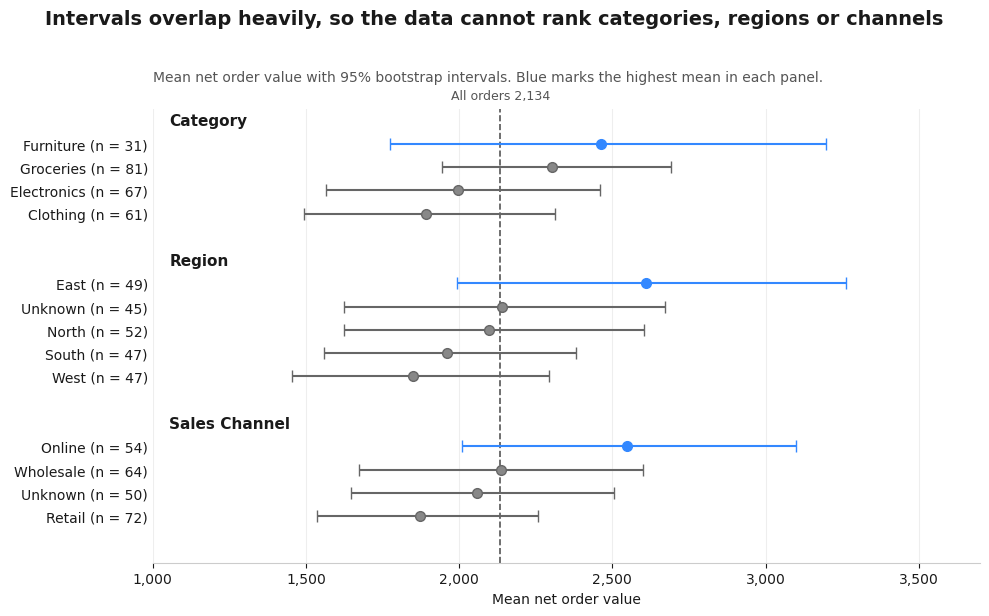

In [145]:
# ---- Bootstrap Setup ----
rng = np.random.default_rng(42)
overall_mean = complete_case['Net_Sales_Amount'].mean()

def bootstrap_ci(values, n_boot=5000, level=0.95):
    values = np.asarray(values, dtype=float)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    lo, hi = np.percentile(means, [(1 - level) / 2 * 100, (1 + level) / 2 * 100])
    return values.mean(), lo, hi

# ---- Calculate CIs ----
ci_data = []
for col in ['Category', 'Region', 'Sales_Channel']:
    for g, d in complete_case.groupby(col):
        m, lo, hi = bootstrap_ci(d['Net_Sales_Amount'])
        ci_data.append({
            'Section': col.replace('_', ' '),
            'Group': f"{g} (n = {len(d)})",
            'Mean': m, 'CI_Low': lo, 'CI_High': hi
        })

# Convert to DataFrame and find the highest mean per section
df_ci = pd.DataFrame(ci_data)
max_means = df_ci.groupby('Section')['Mean'].idxmax()

# ---- Plotting ----
plt.rcParams.update({'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'text.color': '#1a1a1a', 'axes.labelcolor': '#1a1a1a',
                     'xtick.color': '#1a1a1a', 'ytick.color': '#1a1a1a'})

fig, ax = plt.subplots(figsize=(10, 6))

y_pos = 0
y_ticks = []
y_labels = []
section_headers = []

for section in ['Category', 'Region', 'Sales Channel']:
    section_headers.append((y_pos, section))
    y_pos += 1
    
    # Sort groups within section by mean descending for visual clarity
    sec_df = df_ci[df_ci['Section'] == section].sort_values('Mean', ascending=False)
    
    for idx, row in sec_df.iterrows():
        y_ticks.append(y_pos)
        y_labels.append(row['Group'])
        
        # Determine color
        is_highest = idx == max_means[section]
        color = '#3388FF' if is_highest else '#666666'
        marker_face = '#3388FF' if is_highest else '#888888'
        
        # Plot error bars
        ax.errorbar(row['Mean'], y_pos, 
                    xerr=[[row['Mean'] - row['CI_Low']], [row['CI_High'] - row['Mean']]],
                    fmt='o', color=color, ecolor=color, capsize=4, 
                    markerfacecolor=marker_face, markeredgecolor=color, markersize=7)
        
        y_pos += 1
    y_pos += 1

# Formatting Y-axis
ax.set_yticks(y_ticks)
ax.set_yticklabels(y_labels)
ax.set_ylim(y_pos, -0.5) # Invert Y axis

# Add section headers
for y, label in section_headers:
    ax.text(0.02, y, label, fontweight='bold', fontsize=11, va='center', ha='left', transform=ax.get_yaxis_transform())

# Add overall mean reference line
ax.axvline(overall_mean, color='#555555', linestyle='--', linewidth=1.2, zorder=0)
ax.text(overall_mean, -0.8, f"All orders {overall_mean:,.0f}", ha='center', va='bottom', fontsize=9, color='#555555')

# Formatting X-axis
ax.set_xlabel('Mean net order value', fontsize=10)
ax.set_xlim(1000, 3700)
ax.set_xticks([1000, 1500, 2000, 2500, 3000, 3500])
ax.set_xticklabels([f"{x:,}" for x in [1000, 1500, 2000, 2500, 3000, 3500]])

# Remove spines and grid
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#cccccc')
ax.tick_params(axis='y', length=0) # Hide y-axis ticks
ax.grid(axis='x', color='#eeeeee', linestyle='-', linewidth=0.8)

# Titles
plt.suptitle('Intervals overlap heavily, so the data cannot rank categories, regions or channels', 
             x=0.05, y=1.02, ha='left', fontsize=14, fontweight='bold')
ax.set_title('Mean net order value with 95% bootstrap intervals. Blue marks the highest mean in each panel.', 
             loc='left', fontsize=10, color='#555555', pad=20)

plt.tight_layout()
plt.show()


# 4. Influence of Discounts

Orders with a recorded discount: 240 of 240


,Orders,Mean_Quantity,Mean_Unit_Price,Mean_Gross,Mean_Net,Median_Net
Discount,,,,,,
0.0,131,3.0,734.3,2138.8,2138.8,1497.0
5.0,33,2.5,799.2,2122.3,2016.2,1422.2
10.0,43,2.6,827.2,2137.8,1924.0,899.1
15.0,33,3.4,905.5,2949.5,2507.0,2120.8


Kruskal-Wallis of Quantity across discount tiers: p = 0.027
Kruskal-Wallis of Sales_Amount across discount tiers: p = 0.304
Kruskal-Wallis of Net_Sales_Amount across discount tiers: p = 0.387
Spearman Discount vs Quantity: rho = -0.036, p = 0.584
Spearman Discount vs Net_Sales_Amount: rho = -0.015, p = 0.813
Spearman Discount vs Unit_Price (are pricier items discounted more?): rho = 0.123, p = 0.057


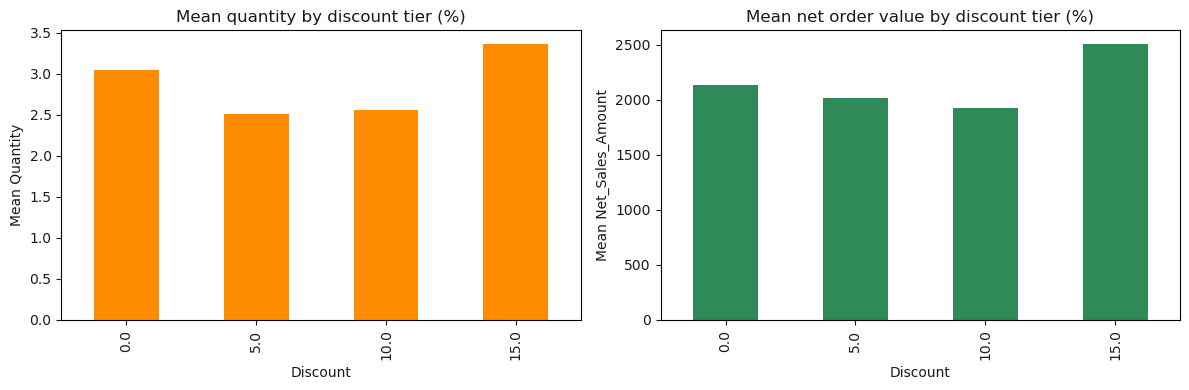

In [146]:
if 'Discount_Recorded' in complete_case.columns:
    disc = complete_case[complete_case['Discount_Recorded']].copy()
else:
    disc = complete_case.copy()
    print('WARNING: Discount_Recorded not found - re-run the imputation cell. Results below include imputed zeros.')
print(f'Orders with a recorded discount: {len(disc)} of {len(complete_case)}')

display(disc.groupby('Discount').agg(Orders=('Quantity', 'size'), Mean_Quantity=('Quantity', 'mean'),
        Mean_Unit_Price=('Unit_Price', 'mean'), Mean_Gross=('Sales_Amount', 'mean'),
        Mean_Net=('Net_Sales_Amount', 'mean'), Median_Net=('Net_Sales_Amount', 'median')).round(1))

for v in ['Quantity', 'Sales_Amount', 'Net_Sales_Amount']:
    H, p = stats.kruskal(*[g[v].values for _, g in disc.groupby('Discount')])
    print(f'Kruskal-Wallis of {v} across discount tiers: p = {p:.3f}')
for v in ['Quantity', 'Net_Sales_Amount']:
    rho, p = stats.spearmanr(disc['Discount'], disc[v])
    print(f'Spearman Discount vs {v}: rho = {rho:.3f}, p = {p:.3f}')
rho, p = stats.spearmanr(disc['Discount'], disc['Unit_Price'])
print(f'Spearman Discount vs Unit_Price (are pricier items discounted more?): rho = {rho:.3f}, p = {p:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
disc.groupby('Discount')['Quantity'].mean().plot(kind='bar', ax=ax[0], color='darkorange')
ax[0].set_title('Mean quantity by discount tier (%)'); ax[0].set_ylabel('Mean Quantity')
disc.groupby('Discount')['Net_Sales_Amount'].mean().plot(kind='bar', ax=ax[1], color='seagreen')
ax[1].set_title('Mean net order value by discount tier (%)'); ax[1].set_ylabel('Mean Net_Sales_Amount')
plt.tight_layout(); plt.show()

results show that discounts are not driving volume
- Discount vs Quantity: ρ = −0.036, p = 0.584 (no relationship)
- Discount vs Net_Sales: ρ = −0.015, p = 0.813 (no relationship)
- Discount vs Unit_Price: ρ = 0.123, p = 0.057 (marginally positive — pricier items get slightly deeper discounts)

**Interpretation:**

Discounting is not producing the classic promotional lift. Customers aren't buying more units when discounts are deeper. Higher discounts do reduce net revenue (mechanically), but they're not compensated by volume. The positive correlation between discount and unit price (p = 0.057) suggests a policy pattern: the retailer discounts expensive items more, perhaps to move slow inventory. This is worth investigating operationally.to conclude if this reflects reality, the discount strategy is value-destroying the bussiness is giving away margin without generating incremental volume.

# 5. Changes in Perfomance over time

,Orders,Revenue,Mean_Order_Value,MoM_Growth_%,Rolling_3M_Revenue
Order_Month,,,,,
2024-01,12,16060.0,1338.0,NaN,NaN
2024-02,17,42947.0,2526.0,167.4,NaN
2024-03,19,46065.0,2424.0,7.3,35024.0
2024-04,13,24099.0,1854.0,-47.7,37704.0
2024-05,21,47980.0,2285.0,99.1,39381.0
2024-06,10,26256.0,2626.0,-45.3,32778.0
2024-07,15,31658.0,2111.0,20.6,35298.0
2024-08,12,19483.0,1624.0,-38.5,25799.0
2024-09,10,24611.0,2461.0,26.3,25251.0


Last order date: 2025-05-15 -> final month is PARTIAL and excluded from the trend test
Monthly revenue trend (Spearman rho vs month index): rho = -0.124, p = 0.649


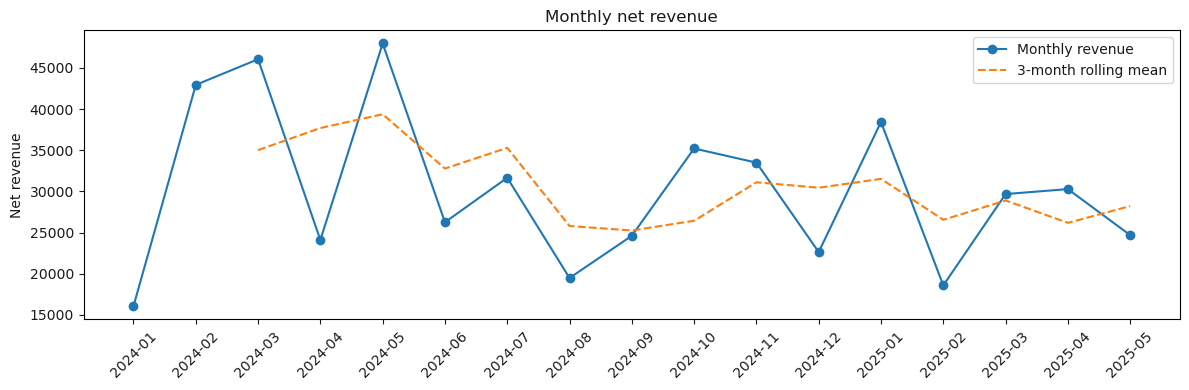

In [147]:
monthly = complete_case.groupby('Order_Month')['Net_Sales_Amount'].agg(Orders='count', Revenue='sum', Mean_Order_Value='mean').round(0)
monthly['MoM_Growth_%'] = (monthly['Revenue'].pct_change() * 100).round(1)
monthly['Rolling_3M_Revenue'] = monthly['Revenue'].rolling(3).mean().round(0)
display(monthly)

last = transact['Order_Date'].max()
partial = last.day < last.days_in_month
print(f'Last order date: {last.date()} -> final month {"is PARTIAL and excluded from the trend test" if partial else "is complete"}')
full = monthly.iloc[:-1] if partial else monthly
rho, p = stats.spearmanr(range(len(full)), full['Revenue'])
print(f'Monthly revenue trend (Spearman rho vs month index): rho = {rho:.3f}, p = {p:.3f}')

x = monthly.index.astype(str)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(x, monthly['Revenue'], marker='o', label='Monthly revenue')
ax.plot(x, monthly['Rolling_3M_Revenue'], linestyle='--', label='3-month rolling mean')
ax.set_title('Monthly net revenue'); ax.set_ylabel('Net revenue'); ax.tick_params(axis='x', rotation=45); ax.legend()
plt.tight_layout(); plt.show()

**Interpretation:** Revenue is noise-dominated and not trend-driven, with <= 14 orders per month, month-to-month variation is dominated by sampling randomness. We cannot claim growth or decline from this data.

# 6. Customer purchasing behaviour

,Orders,Revenue,Avg_Order_Value,Avg_Quantity,Revenue_Share_%
Customer_Name,,,,,
Ahmed,25,64638.0,2586.0,3.0,12.6
John,25,60116.0,2405.0,3.0,11.7
Sam,26,56276.0,2164.0,3.0,11.0
Emily,35,55670.0,1591.0,3.0,10.9
Wei,21,55086.0,2623.0,3.0,10.8
Chen,23,50720.0,2205.0,3.0,9.9
Asha,26,46085.0,1773.0,3.0,9.0
Ali,21,44109.0,2100.0,3.0,8.6
Riya,21,42459.0,2022.0,3.0,8.3


Kruskal-Wallis of order value across customers: p = 0.482
Orders per customer, all 500 orders: {'min': 39.0, 'median': 49.5, 'max': 63.0}


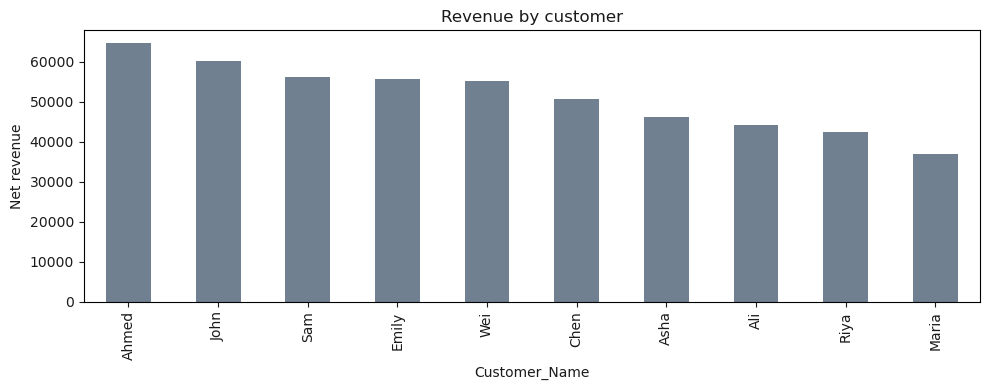

In [148]:
cust = complete_case.groupby('Customer_Name').agg(Orders=('Order_ID', 'count'), Revenue=('Net_Sales_Amount', 'sum'),
        Avg_Order_Value=('Net_Sales_Amount', 'mean'), Avg_Quantity=('Quantity', 'mean')).round(0)
cust['Revenue_Share_%'] = (cust['Revenue'] / cust['Revenue'].sum() * 100).round(1)
display(cust.sort_values('Revenue', ascending=False))

H, p = stats.kruskal(*[g['Net_Sales_Amount'].values for _, g in complete_case.groupby('Customer_Name')])
print(f'Kruskal-Wallis of order value across customers: p = {p:.3f}')
print('Orders per customer, all 500 orders:', transact.groupby('Customer_Name').size().agg(['min', 'median', 'max']).to_dict())

cust.sort_values('Revenue', ascending=False)['Revenue'].plot(kind='bar', figsize=(10, 4), color='slategray')
plt.title('Revenue by customer'); plt.ylabel('Net revenue'); plt.tight_layout(); plt.show()

10 customers, each contributing 7–13% of revenue
- Kruskal-Wallis across customers: p = 0.482 (no significant differences)
- Orders per customer: min 39, median 49.5, max 63

Revenue is evenly distributed across customers there is no star customer. 

# 7. High and low perfoming areas and concentration

Top 10% of orders generate 28.7% of revenue
Top 20% of orders generate 48.8% of revenue
Top 50% of orders generate 81.7% of revenue


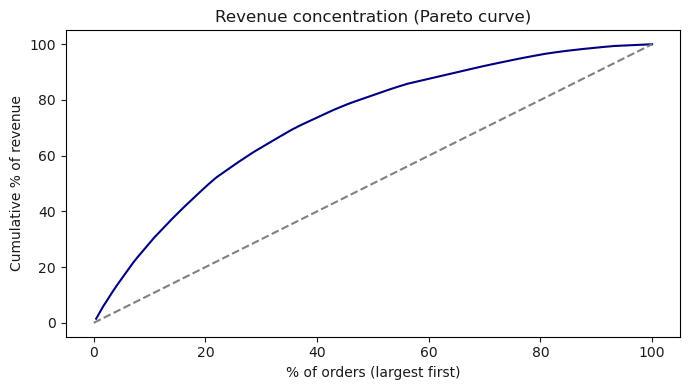


IQR upper fence = 6,167; orders above it: 10


,Category,Product,Quantity,Unit_Price,Discount,Net_Sales_Amount
11,Groceries,Bananas,5.0,1500.0,0.0,7500.0
145,Electronics,Laptop,5.0,1500.0,15.0,6375.0
175,Groceries,Bananas,5.0,1500.0,0.0,7500.0
233,Groceries,Bananas,5.0,1500.0,15.0,6375.0
341,Clothing,Jeans,5.0,1500.0,15.0,6375.0
351,Furniture,Chair,5.0,1500.0,10.0,6750.0
352,Furniture,Chair,5.0,1500.0,0.0,7500.0
458,Electronics,Tablet,5.0,1500.0,0.0,7500.0
478,Electronics,Mobile,5.0,1500.0,10.0,6750.0
492,Electronics,Laptop,5.0,1500.0,10.0,6750.0


In [149]:
s = complete_case['Net_Sales_Amount'].sort_values(ascending=False).reset_index(drop=True)
cum = s.cumsum() / s.sum()
for q in [0.1, 0.2, 0.5]:
    print(f'Top {q:.0%} of orders generate {cum.iloc[int(len(s) * q) - 1]:.1%} of revenue')

plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, len(s) + 1) / len(s) * 100, cum * 100, color='navy')
plt.plot([0, 100], [0, 100], linestyle='--', color='grey')
plt.xlabel('% of orders (largest first)'); plt.ylabel('Cumulative % of revenue'); plt.title('Revenue concentration (Pareto curve)')
plt.tight_layout(); plt.show()

# outliers
q1, q3 = rev.quantile([0.25, 0.75]); fence = q3 + 1.5 * (q3 - q1)
out = complete_case[complete_case['Net_Sales_Amount'] > fence]
print(f'\nIQR upper fence = {fence:,.0f}; orders above it: {len(out)}')
display(out[['Category', 'Product', 'Quantity', 'Unit_Price', 'Discount', 'Net_Sales_Amount']])

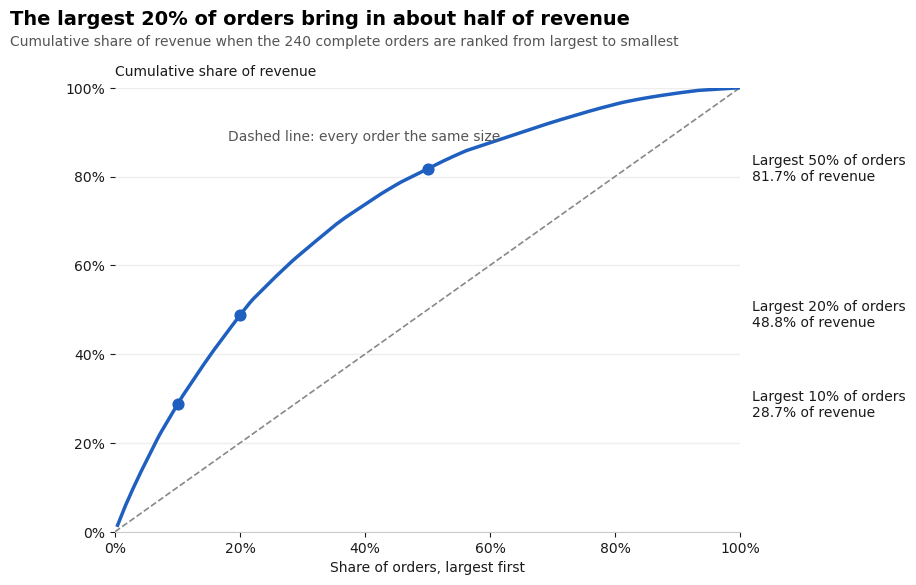

In [158]:
# ---- 1. Use your existing s and cum ----
# (Assuming s and cum are already defined in your kernel from your previous cell)
x_pct = np.arange(1, len(s) + 1) / len(s) * 100
y_pct = cum * 100

# Get exact values for the key percentiles using your existing cum variable
q10_val = cum.iloc[int(len(s) * 0.1) - 1] * 100
q20_val = cum.iloc[int(len(s) * 0.2) - 1] * 100
q50_val = cum.iloc[int(len(s) * 0.5) - 1] * 100

# ---- 2. Plotting (White Theme) ----
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': '#1a1a1a', 'axes.labelcolor': '#1a1a1a',
    'xtick.color': '#1a1a1a', 'ytick.color': '#1a1a1a'
})

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the main curve
ax.plot(x_pct, y_pct, color='#1f5fbf', linewidth=2.5, zorder=3)

# Plot the dashed equality line
ax.plot([0, 100], [0, 100], linestyle='--', color='#888888', linewidth=1.2, zorder=2)

# Add markers at 10%, 20%, 50%
for x_mark, y_mark in [(10, q10_val), (20, q20_val), (50, q50_val)]:
    ax.scatter(x_mark, y_mark, color='#1f5fbf', s=60, zorder=4)

# ---- 3. Formatting & Styling ----
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xticks([0, 20, 40, 60, 80, 100])
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.set_xticklabels([f'{int(x)}%' for x in ax.get_xticks()], fontsize=10)
ax.set_yticklabels([f'{int(y)}%' for y in ax.get_yticks()], fontsize=10)

# Remove top, right, and left spines; lighten bottom spine
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)
ax.spines['bottom'].set_color('#cccccc')

# Add light horizontal grid lines only
ax.yaxis.grid(True, color='#eeeeee', linestyle='-', linewidth=1)
ax.set_axisbelow(True)

# ---- 4. Annotations ----
fig.suptitle('The largest 20% of orders bring in about half of revenue', 
             x=0.02, y=0.98, ha='left', fontsize=14, fontweight='bold', color='black')
fig.text(0.02, 0.92, f'Cumulative share of revenue when the {len(s)} complete orders are ranked from largest to smallest', 
         ha='left', fontsize=10, color='#555555')

ax.set_xlabel('Share of orders, largest first', fontsize=10)
ax.text(0, 102, 'Cumulative share of revenue', fontsize=10, ha='left', va='bottom')

ax.text(18, 88, 'Dashed line: every order the same size', fontsize=10, color='#555555')

# Right-side callout annotations using your existing s and cum
trans = ax.get_yaxis_transform()
ax.text(1.02, q50_val, f'Largest 50% of orders\n{q50_val:.1f}% of revenue', 
        transform=trans, ha='left', va='center', fontsize=10)
ax.text(1.02, q20_val, f'Largest 20% of orders\n{q20_val:.1f}% of revenue', 
        transform=trans, ha='left', va='center', fontsize=10)
ax.text(1.02, q10_val, f'Largest 10% of orders\n{q10_val:.1f}% of revenue', 
        transform=trans, ha='left', va='center', fontsize=10)

plt.subplots_adjust(top=0.85, right=0.75)
plt.show()

# 8. Unexpected patterns

In [150]:
print(f"Orders with no revenue data: {(~transact['Valid_Sale']).sum()} of {len(transact)} ({(~transact['Valid_Sale']).mean():.1%})")
print(f"Orders with Unknown region: {(transact['Region'] == 'Unknown').mean():.1%} | Unknown channel: {(transact['Sales_Channel'] == 'Unknown').mean():.1%}")
if 'Discount_Recorded' in transact.columns:
    print(f"Orders with no recorded discount: {(~transact['Discount_Recorded']).mean():.1%}")

share = transact.groupby('Region')['Valid_Sale'].agg(Orders='size', Complete_Share='mean').round(3)
display(share)

Orders with no revenue data: 260 of 500 (52.0%)
Orders with Unknown region: 19.8% | Unknown channel: 23.6%


,Orders,Complete_Share
Region,,
East,105,0.467
North,105,0.495
South,93,0.505
Unknown,99,0.455
West,98,0.480


# 9. How certain are the group differences? Bootstrap confidence intervals

The Kruskal-Wallis tests only say whether groups differ significantly. Bootstrap 95% confidence intervals for mean order value show how large the uncertainty is. If the intervals overlap heavily, the data cannot separate the groups. Each interval comes from 5,000 resamples of the group's orders, drawn with replacement.

 Category 


,Orders,Mean_Order_Value,CI_Low,CI_High
Category,,,,
Furniture,31,2462,1776,3197
Groceries,81,2305,1945,2692
Electronics,67,1996,1566,2461
Clothing,61,1893,1493,2313


 Region 


,Orders,Mean_Order_Value,CI_Low,CI_High
Region,,,,
East,49,2610,1994,3262
Unknown,45,2139,1625,2674
North,52,2097,1626,2602
South,47,1960,1560,2380
West,47,1849,1454,2292


 Sales_Channel 


,Orders,Mean_Order_Value,CI_Low,CI_High
Sales_Channel,,,,
Online,54,2549,2010,3099
Wholesale,64,2137,1674,2599
Unknown,50,2059,1646,2505
Retail,72,1872,1538,2256


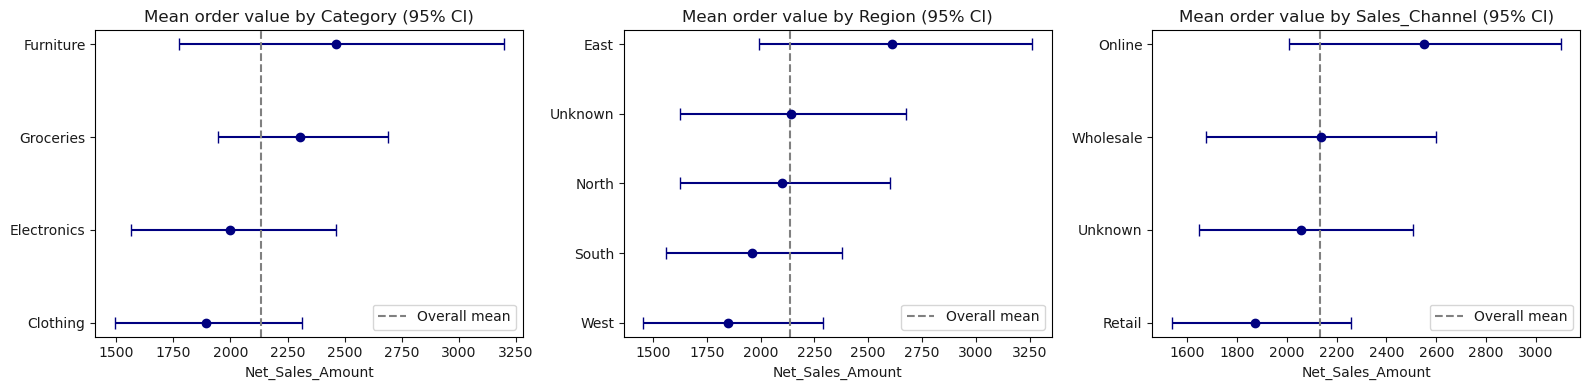

In [151]:
rng = np.random.default_rng(42)

def bootstrap_ci(values, n_boot=5000, level=0.95):
    values = np.asarray(values, dtype=float)
    means = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    lo, hi = np.percentile(means, [(1 - level) / 2 * 100, (1 + level) / 2 * 100])
    return values.mean(), lo, hi

overall_mean = complete_case['Net_Sales_Amount'].mean()
ci_tables = {}
for col in ['Category', 'Region', 'Sales_Channel']:
    rows = []
    for g, d in complete_case.groupby(col):
        m, lo, hi = bootstrap_ci(d['Net_Sales_Amount'])
        rows.append({col: g, 'Orders': len(d), 'Mean_Order_Value': round(m), 'CI_Low': round(lo), 'CI_High': round(hi)})
    ci_tables[col] = pd.DataFrame(rows).set_index(col).sort_values('Mean_Order_Value', ascending=False)
    print(f' {col} ')
    display(ci_tables[col])

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ci_tables):
    t = ci_tables[col].iloc[::-1]
    ax.errorbar(t['Mean_Order_Value'], range(len(t)),
                xerr=[t['Mean_Order_Value'] - t['CI_Low'], t['CI_High'] - t['Mean_Order_Value']],
                fmt='o', color='navy', capsize=4)
    ax.axvline(overall_mean, linestyle='--', color='grey', label='Overall mean')
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index)
    ax.set_title(f'Mean order value by {col} (95% CI)'); ax.set_xlabel('Net_Sales_Amount'); ax.legend()
plt.tight_layout(); plt.show()

# 10. Sensitivity check: complete-case versus multiple imputation

The group comparisons are repeated on the multiple-imputation dataset (`pooled`, n = 500) to see whether the conclusions depend on how the incomplete orders are handled. Matching results under both approaches make the findings more reliable.

In [152]:
if 'pooled' not in globals():
    print('pooled not found - run the multiple-imputation cell first')
else:
    rows = []
    for label, data in [('Complete-case (n=%d)' % len(complete_case), complete_case), ('MI-pooled (n=%d)' % len(pooled), pooled)]:
        for col in ['Category', 'Region', 'Sales_Channel']:
            H, p, eps2 = kruskal_summary(data, col)
            top = data.groupby(col)['Net_Sales_Amount'].mean().idxmax()
            rows.append({'Dataset': label, 'Grouping': col, 'H': round(H, 2), 'p_value': round(p, 3),
                         'epsilon_sq': round(eps2, 3), 'Highest_mean_order_value': top})
    display(pd.DataFrame(rows))

,Dataset,Grouping,H,p_value,epsilon_sq,Highest_mean_order_value
0,Complete-case (n=240),Category,4.58,0.206,0.007,Furniture
1,Complete-case (n=240),Region,1.62,0.805,0.000,East
2,Complete-case (n=240),Sales_Channel,2.96,0.398,0.000,Online
3,MI-pooled (n=500),Category,2.83,0.419,0.000,Furniture
4,MI-pooled (n=500),Region,4.81,0.307,0.002,East
5,MI-pooled (n=500),Sales_Channel,0.94,0.815,0.000,Online


**Intepretation:** Both approaches agree there is no significant differences, same ranking of groups. This is the strongest evidence that missingness handling doesn't change conclusions. The MI dataset (n = 500) has slightly different p-values because it has more data, but the story is identical

# 11. Do category, region and channel explain order value? (OLS regression)

In [153]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

reg = complete_case.copy()
reg['Log_Order_Value'] = np.log(reg['Net_Sales_Amount'])
ref = {c: reg[c].value_counts().idxmax() for c in ['Category', 'Region', 'Sales_Channel']}
print('Reference groups:', ref)
rhs = ' + '.join(f"C({c}, Treatment(reference='{ref[c]}'))" for c in ref)

summary_rows, models = [], {}
for outcome in ['Log_Order_Value', 'Quantity', 'Unit_Price']:
    m = smf.ols(f'{outcome} ~ {rhs}', data=reg).fit(cov_type='HC3')
    models[outcome] = m
    summary_rows.append({'Outcome': outcome, 'n': int(m.nobs), 'R_squared': round(m.rsquared, 3),
                         'Adj_R_squared': round(m.rsquared_adj, 3), 'Overall_F_p': round(m.f_pvalue, 3)})
display(pd.DataFrame(summary_rows))

Reference groups: {'Category': 'Groceries', 'Region': 'North', 'Sales_Channel': 'Retail'}


,Outcome,n,R_squared,Adj_R_squared,Overall_F_p
0,Log_Order_Value,240,0.038,-0.004,0.427
1,Quantity,240,0.013,-0.031,0.984
2,Unit_Price,240,0.043,0.001,0.460


In [154]:
import re
# Coefficients for the order-value model, as % difference from the reference group
m = models['Log_Order_Value']
ci = m.conf_int()
coef = pd.DataFrame({'Pct_diff_vs_ref': ((np.exp(m.params) - 1) * 100).round(1),
                     'CI_low_%': ((np.exp(ci[0]) - 1) * 100).round(1),
                     'CI_high_%': ((np.exp(ci[1]) - 1) * 100).round(1),
                     'p_value': m.pvalues.round(3)}).drop('Intercept')
coef.index = [re.sub(r"C\((\w+), Treatment\(reference='(.+?)'\)\)\[T\.(.+?)\]", r'\1: \3 vs \2', i) for i in coef.index]
display(coef)

# Does each factor matter as a whole? (joint F-test per factor)
plain = smf.ols(f'Log_Order_Value ~ {rhs}', data=reg).fit()
joint = anova_lm(plain, typ=2)[['F', 'PR(>F)']].round(3).drop('Residual')
joint.index = [c.split(',')[0].replace('C(', '') for c in joint.index]
display(joint)

,Pct_diff_vs_ref,CI_low_%,CI_high_%,p_value
Category: Clothing vs Groceries,-20.7,-42.0,8.6,0.148
Category: Electronics vs Groceries,-19.8,-42.1,11.1,0.185
Category: Furniture vs Groceries,1.2,-34.2,55.6,0.957
Region: East vs North,17.3,-20.4,72.8,0.419
Region: South vs North,0.4,-29.6,43.2,0.981
Region: Unknown vs North,-5.3,-36.6,41.5,0.792
Region: West vs North,-6.6,-34.6,33.6,0.710
Sales_Channel: Online vs Retail,35.6,-2.7,88.8,0.072
Sales_Channel: Unknown vs Retail,15.3,-16.2,58.8,0.382
Sales_Channel: Wholesale vs Retail,2.7,-28.1,46.6,0.884


,F,PR(>F)
Category,1.148,0.331
Region,0.436,0.783
Sales_Channel,1.236,0.297


Excluding Unknown region/channel: n = 155, R-squared = 0.071, adj R-squared = 0.020, overall F p = 0.144


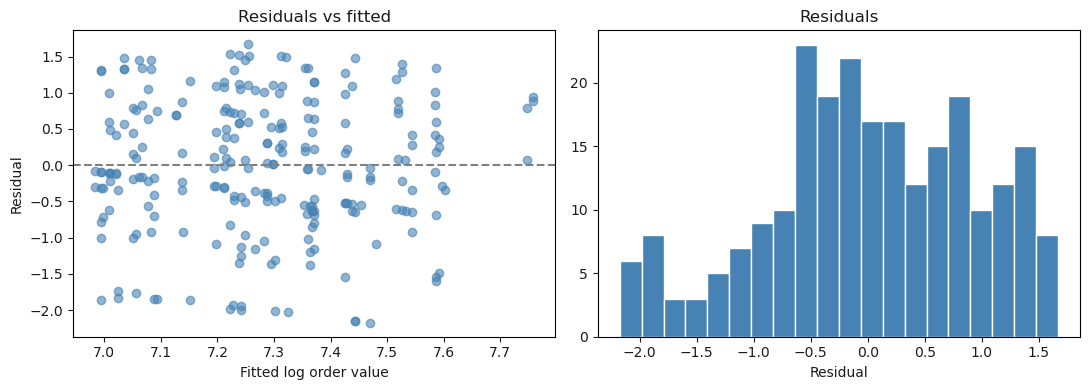

In [155]:
# Robustness: repeat the order-value model without 'Unknown' region/channel orders
known_only = reg[(reg['Region'] != 'Unknown') & (reg['Sales_Channel'] != 'Unknown')]
rhs_k = ' + '.join(f"C({c}, Treatment(reference='{ref[c]}'))" for c in ref)
mk = smf.ols(f'Log_Order_Value ~ {rhs_k}', data=known_only).fit(cov_type='HC3')
print(f'Excluding Unknown region/channel: n = {int(mk.nobs)}, R-squared = {mk.rsquared:.3f}, adj R-squared = {mk.rsquared_adj:.3f}, overall F p = {mk.f_pvalue:.3f}')

# Diagnostics for the order-value model
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(plain.fittedvalues, plain.resid, alpha=0.6, color='steelblue')
ax[0].axhline(0, color='grey', linestyle='--'); ax[0].set_title('Residuals vs fitted'); ax[0].set_xlabel('Fitted log order value'); ax[0].set_ylabel('Residual')
ax[1].hist(plain.resid, bins=20, color='steelblue', edgecolor='white'); ax[1].set_title('Residuals'); ax[1].set_xlabel('Residual')
plt.tight_layout(); plt.show()

- Log_Order_Value: R² = 0.038, adj R² = −0.004, F p = 0.427
- Quantity: R² = 0.013, adj R² = −0.031, F p = 0.984
- Unit_Price: R² = 0.043, adj R² = 0.001, F p = 0.460

**Interpretation:**
- Category, Region, and Sales_Channel together explain essentially none of the variance in order value
- The adjusted R² is negative for Log_Order_Value and Quantity, meaning the model performs worse than just using the mean
- The coefficient table shows wide confidence intervals (e.g., "Online vs Retail" shows +35.6% but with CI −2.7% to +88.8%). The point estimate is large but completely unreliable.
- The joint F-tests confirm: no factor matters as a whole (all p > 0.29).
- The residual plots look fine (no obvious heteroscedasticity or non-linearity), which means the model isn't misspecified, it's just that there's nothing to find.